# 01 · Core concepts: populations, neuron models & parameters

In [00 · Welcome to py-spinnaker2](./00_welcome.ipynb) you built and ran two networks. Here we slow down and
look closely at the first building block — the **[`Population`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/snn-api.html#spinnaker2.snn.Population)** — and the two components that
define it: **neuron model** and **parameters**.

**By the end of this notebook you will be able to:**

- create populations and know every argument the `Population` constructor takes,
- list the neuron models py-spinnaker2 ships with and inspect any model's parameters,
- set shared parameters **per population** or individual **per neuron**, and
  know which ones are which.

> **Info**
>
> Same as before: everything runs on the Brian2 simulator by default — flip `USE_HARDWARE` to run on a board.

In [1]:
from spinnaker2 import snn, helpers, brian2_sim
import numpy as np
import matplotlib.pyplot as plt

USE_HARDWARE = True

if USE_HARDWARE:
    from spinnaker2 import hardware

    hw = hardware.SpiNNcloud48NodeBoard()  # or hardware.SpiNNaker2Chip()
else:
    hw = brian2_sim.Brian2Backend()

print("Running on backend:", type(hw).__name__)

INFO:     Path to spinnaker configuration directory found in global config path /etc/opt/spinnaker/SPINNAKER_CONFIG_PATH


Running on backend: SpiNNcloud48NodeBoard


## 1. Population

A population is a group of neurons that share one **neuron model**. Its constructor:

```python
snn.Population(
    size=...,          # int   — number of neurons
    neuron_model=...,  # str   — which model (see the next section)
    params=...,        # dict  — parameters for the model (shared or per-neuron)
    name=...,          # str   — optional; auto-named if omitted
    record=[...],      # list  — variables to record, e.g. ["spikes", "v"]
    record_on_dram=..  # bool  — store recordings in DRAM (for long runs / many neurons)
)
```

- **`record`** defaults to `[]`. Common values: `"spikes"`, `"v"` (full voltage trace),
  `"v_last"` (voltage at the final step only), `"time_done"` (per-step execution time —
  useful for profiling). Which ones are valid depends on the model.
- By default, recorded values are stored in the local SRAM of each Processing Element (PE) → small but fast.
**`record_on_dram=True`** moves recordings to DRAM so you can record more / for longer time → larger than SRAM but slightly slower. What a PE actually is, and SRAM vs. DRAM on it, is covered fully in [06 · Hardware architecture](./06_hardware_architecture.ipynb).

Spike-source populations (like [`"spike_list"`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#spike-list-spike_list)) are also `Population`s — they just use a
model that only replays or generates spikes instead of integrating inputs.

## 2. Neuron models

A model is selected by name (the `neuron_model=` string). py-spinnaker2 discovers its
models from a registry — let's list what's available in this installation:

In [2]:
from spinnaker2.neuron_models import NEURON_MODEL_TO_APPLICATION, NeuronModelRegistry

NeuronModelRegistry()  # populate the registry (happens automatically on first use)

print(f"{len(NEURON_MODEL_TO_APPLICATION)} neuron models available:\n")
for name in sorted(NEURON_MODEL_TO_APPLICATION):
    print("  ", name)

29 neuron models available:

   alif
   alif_32bit
   alif_no_delay
   alif_no_delay_1024
   charge_and_spike
   conv2d_if_neuron_rate_code
   gather_and_stream
   izhikevich
   izhikevich_32bit
   lif
   lif_32bit
   lif_conv2d
   lif_curr_exp
   lif_curr_exp_32bit
   lif_curr_exp_no_delay
   lif_no_delay
   lif_no_delay_1024
   lif_prob
   lif_prob_32bit
   lif_prob_no_delay
   lif_prob_no_delay_1024
   poisson_process
   qubo_neuron
   qubo_neuron_32bit
   relay
   spike_list
   spike_receiver
   spike_replicator
   spikes_from_array_latency_code


#### Core models & variants

The list is long, but most names are **variants of a handful of core models**. A variant changes the *hardware budget* a model runs under — there are three settings:

- **weight precision** — bits per synaptic weight (wider = finer weights, but more memory),
- **synaptic delay** — whether the processing of incoming spikes can be delayed, and by how many timesteps,
- **neurons per core** — how many fit on one processing element (PE).

For example the baseline **[`lif`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#leaky-integratefire-neuron-lif)** uses 5-bit weights (range = [-15, +15]), delays of 0–7 steps, and up to **256 neurons per core**. The variants just rebalance those budgets:

- **`lif_no_delay`** — drops delays to afford **8-bit** weights;
- **`lif_no_delay_1024`** — gives up delays *and* weight range to pack **1024** neurons per core;
- **`lif_32bit`** — spends memory on **20-bit** weights.

You don't need to memorise any of this — every model reports its own budgets and parameters:

In [3]:
from spinnaker2.neuron_models import get_application

for name in ["lif", "lif_curr_exp", "izhikevich"]:
    app = get_application(name)
    sw = app.sw_spec  # synapse word layout: how many bits each field gets
    print(f"{name}")
    print(f"   parameters : {list(app.default_params)}")
    print(f"   recordables: {app.recordables()}")
    print(f"   max neurons / core: {app.max_atoms_per_core}")
    print(f"   weight range: [-{sw.max_weight()}, {sw.max_weight()}]  ({sw.weight_bits}-bit magnitude + sign)")
    print(f"   delay range : 0..{sw.max_delay()} steps  ({sw.delay_bits}-bit)")
    print(f"   global params: reset={hasattr(app, 'reset')}, seed={hasattr(app, 'seed')}")
    print()

lif
   parameters : ['alpha_decay', 'threshold', 'i_offset', 'v_init', 'v_reset']
   recordables: ['spikes', 'v', 'time_done']
   max neurons / core: 256
   weight range: [-15, 15]  (4-bit magnitude + sign)
   delay range : 0..7 steps  (3-bit)
   global params: reset=True, seed=False

lif_curr_exp
   parameters : ['alpha_decay', 'threshold', 'i_offset', 'v_init', 'v_reset', 'exc_decay', 'inh_decay', 't_refract']
   recordables: ['spikes', 'v', 'time_done']
   max neurons / core: 256
   weight range: [-15, 15]  (4-bit magnitude + sign)
   delay range : 0..7 steps  (3-bit)
   global params: reset=True, seed=False

izhikevich
   parameters : ['recovery_decay', 'recovery_sensitivity', 'v_reset', 'reset_recovery_increment', 'i_offset', 'v_init']
   recordables: ['spikes', 'v', 'time_done']
   max neurons / core: 256
   weight range: [-15, 15]  (4-bit magnitude + sign)
   delay range : 0..7 steps  (3-bit)
   global params: reset=False, seed=False



Reading that output:

- **parameters** — model parameters set through `Population`'s `params`.
- **recordables** — base names of simulation variables to record; the corresponding "_last" forms (e.g. `"v_last"`) are available for each base recordable except `"spikes"` and record *only* the final step. `"spikes"` are always recorded for the entire simulation.
- **max neurons / core** — the capacity budget from above: `256` for `lif`, `1024` for the `_1024` variants.
- **weight range / delay range** — the synapse budgets from §2.1, read straight off the model: `lif` carries a signed weight in `[-15, 15]` and delays of `0–7` steps. The bit count shown is the weight *magnitude*; a separate sign bit supplies the negative half of the range. The `_no_delay` / `_1024` / `_32bit` variants trade these budgets around.
- `reset` and `seed` are **global** parameters (next section), so they show up separately, not in the per-neuron list.

Beyond the LIF variants, the other model families are:

- **[`lif_curr_exp`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#leaky-integratefire-neuron-with-exponentially-decaying-current-input-lif_curr_exp)** — current-based LIF with exponentially-decaying synapses ([00 · Welcome to py-spinnaker2](./00_welcome.ipynb)'s synfire model), with the same variant family.
- **[`alif`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#leaky-integratefire-neuron-with-adaptive-threshold-alif)** — LIF with an *adaptive threshold* that rises after each spike.
- **[`izhikevich`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#izhikevich-neuron-model-izhikevich)** — richer two-variable dynamics, many firing patterns ([Izhikevich, 2003](https://doi.org/10.1109/TNN.2003.820440)).
- **[`lif_prob`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#probabilistic-lif-neuron-lif_prob)** — fires *probabilistically* once the threshold is crossed.
- **Spike sources** (generate input spikes for other populations, no integration): `spike_list` (fixed times), [`poisson_process`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#poisson-generator-poisson_process) (random), [`spikes_from_array_latency_code`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#spikes-from-array-values-according-to-latency-code-spikes_from_array_latency_code) (latency-coded).
- **Utility / specialised**: [`relay`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#relay-neuron-relay), [`spike_replicator`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#spike-replicator-spike_replicator) & [`gather_and_stream`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#gather-and-stream-gas) (real-time streaming — [07 · Streaming spikes in real time](./07_streaming.ipynb)), [`lif_conv2d`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#leaky-integratefire-neuron-with-incoming-conv2dprojection-lif_conv2d) (convolutions), [`qubo_neuron`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#qubo-neuron-qubo_neuron) (optimisation), [`charge_and_spike`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#chargespike-neuron-charge_and_spike).

Full equations and weight/delay bit-widths for every model: [`docs/api_reference/neuron-models.md`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html).

## 3. Parameters: shared vs. per-neuron vs. global

The `params` dict is where you configure a model. Each value can be either:

- a **scalar** → the value is **shared** by every neuron in the population,
- a **list of length `size`** → one value **per neuron**, or
- a **global parameter** — a couple of settings (`reset`, `seed`) are fixed for the whole population and **can't** be per-neuron (everything in a model's `default_params` can be).

You can mix them in the same dict:

```python
params = {
    "threshold":   1.0,                      # scalar  → shared by all neurons
    "alpha_decay": [0.6, 0.7, 0.8, 0.9],     # list    → one per neuron
    "i_offset":    [0.0, 0.1, 0.2, 0.3],     # list    → one per neuron
    "reset":       "reset_to_v_reset",       # global  → one value for the whole population
}
```

### 3.1 Spike sources (`spike_list`)

One family of neuron models behaves differently from the rest. **Spike sources** like `spike_list` don't *integrate* inputs — they simply replay spikes you define — so their `params` is **not** the usual `{parameter: value}` dictionary. Instead it maps **neuron index → list of spike times**:

```python
stim = snn.Population(
    size=3,
    neuron_model="spike_list",
    params={0: [1, 4, 9], 2: [20, 25]},   # neurons 0 and 2 fire at these steps; neuron 1 stays silent
    name="stim",
)
```

- Each **key** is a neuron index; its **value** is the time steps at which that neuron fires.
- Neurons not listed simply never spike.
- There are no tunable model parameters (its `default_params` is empty), and no `v` to record — you already know when it spikes.

You already used this in [00 · Welcome to py-spinnaker2](./00_welcome.ipynb): both the stimulus and the synfire "kick" were `spike_list` populations.

### 3.2 Demo: per-neuron parameters

**What we're showing:** that a single `params` dict can give every neuron its *own* value, turning one population into a set of different neurons — and what that looks like.

**What we build:** 12 LIF neurons with *no input spikes at all*. Each neuron's only drive is a constant external input current, `i_offset` (conceptually a simplified stand-in for combined synaptic input from other neurons), ramped from weak (just enough to fire) to strong. Everything else (`threshold`, `alpha_decay`, `reset`) is shared.

**What we expect:** stronger current → faster firing, so firing rate should rise steadily with `i_offset`.

In [4]:
N = 12
i_offsets = np.linspace(0.1, 0.6, N)  # a different constant drive for each neuron

params = {
    "threshold": 1.0,  # shared
    "alpha_decay": 0.9,  # shared
    "i_offset": list(i_offsets),  # per-neuron (list of length N)
    "reset": "reset_by_subtraction",  # global
}

pop = snn.Population(
    size=N,
    neuron_model="lif",
    params=params,
    name="neurons",
    record=["spikes"],
)

net = snn.Network("demo")
net.add(pop)

timesteps = 100
hw.run(net, timesteps)
print("done")

Number of cores needed: 1
Number of available cores: 7104
Sim duration: 0.11 s


Recording post-processing duration: 0 s
done


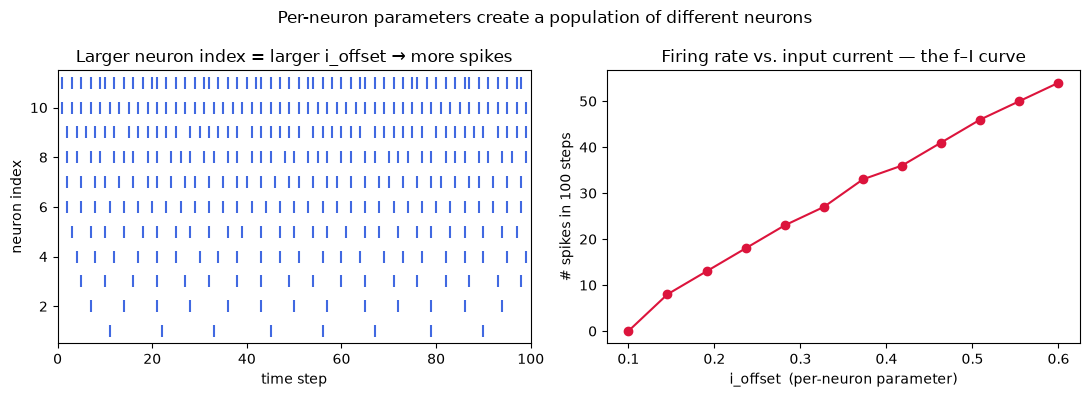

In [5]:
spikes = pop.get_spikes()
counts = [len(spikes.get(i, [])) for i in range(N)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# raster: one row per neuron
idx, timestep = helpers.spike_times_dict_to_arrays(spikes)
ax1.plot(timestep, idx, "|", ms=8, mew=1.5, color="royalblue")
ax1.set_xlabel("time step")
ax1.set_ylabel("neuron index")
ax1.set_xlim(0, timesteps)
ax1.set_title("Larger neuron index = larger i_offset → more spikes")

# firing rate vs the per-neuron parameter
ax2.plot(i_offsets, counts, "o-", color="crimson")
ax2.set_xlabel("i_offset  (per-neuron parameter)")
ax2.set_ylabel(f"# spikes in {timesteps} steps")
ax2.set_title("Firing rate vs. input current — the f–I curve")

fig.suptitle("Per-neuron parameters create a population of different neurons")
plt.tight_layout()
plt.show()

**What you're seeing:** a single population, one neuron model, one `params` dict — but
because `i_offset` was a *list*, each neuron got its own drive and so its own firing rate.
The right panel is essentially the neuron's **frequency–current (f–I) curve**, traced out
across the population in one run.

> **Tip**
>
> 👉 **Try it yourself:** make `alpha_decay` per-neuron instead (e.g.
> `np.linspace(0.85, 0.95, N)`) with a shared `i_offset`, and see how the leak rate changes
> firing. Or switch `neuron_model` to `"alif"` and watch the adaptive threshold slow each
> neuron down over time.

## Recap & what's next

You now know how to:

- create a `Population` and what each constructor argument does,
- **list and inspect** the available neuron models (`NEURON_MODEL_TO_APPLICATION`,
  `get_application(name).default_params` / `.recordables()`),
- set parameters **shared** (scalar) or **per-neuron** (list of length `size`), and which
  parameters are global-only (`reset`, `seed`).

**Next up — [02 · Connectivity](./02_connectivity.ipynb):** wiring populations together with
projections — connection lists, weights and delays in depth, and connection patterns.